# 1ο Εργαστήριο Όρασης Υπολογιστών

*   Μαρία Μαγδαληνή Πλιάτσικα, 03121220
*   Αλέξανδρα Καραλή, 03121084
---
# Μέρος 1

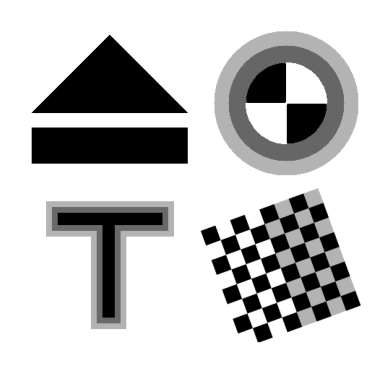

In [1]:
#1.1.1
import cv2
import matplotlib.pyplot as plt

# Διαβάζουμε την εικόνα σε γκρίζα κλίμακα
I0 = cv2.imread("edgetest_25.png", cv2.IMREAD_GRAYSCALE)

# Εμφανίζουμε την εικόνα 
plt.imshow(I0, cmap='gray')
plt.axis("off")
plt.show()

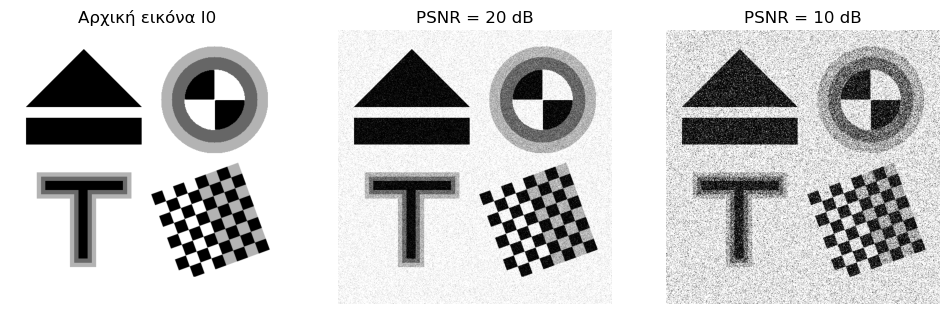

In [2]:
#1.1.2
import numpy as np

# Υπολογισμός Imax και Imin
Imax = np.max(I0)
Imin = np.min(I0)

# Συνάρτηση για προσθήκη Gaussian θορύβου με δεδομένο PSNR
def add_gaussian_noise(image, psnr):
    sigma_n = (Imax - Imin) / (10**(psnr / 20))  # Υπολογισμός τυπικής απόκλισης θορύβου
    noise = np.random.normal(0, sigma_n, image.shape)  
    noisy_image = np.clip(image + noise, 0, 255)  
    #return noisy_image.astype(np.uint8)
    return noisy_image

# Δημιουργία εικόνων για PSNR = 20dB και PSNR = 10dB
I_20dB = add_gaussian_noise(I0, 20)
I_10dB = add_gaussian_noise(I0, 10)

# Εμφάνιση των εικόνων
fig, ax = plt.subplots(1, 3, figsize=(12, 5))
ax[0].imshow(I0, cmap="gray")
ax[0].set_title("Αρχική εικόνα I0")
ax[0].axis("off")

ax[1].imshow(I_20dB, cmap="gray")
ax[1].set_title("PSNR = 20 dB")
ax[1].axis("off")

ax[2].imshow(I_10dB, cmap="gray")
ax[2].set_title("PSNR = 10 dB")
ax[2].axis("off")

plt.show()

Linear Edge Detection (Αρχική Εικόνα Ι0)


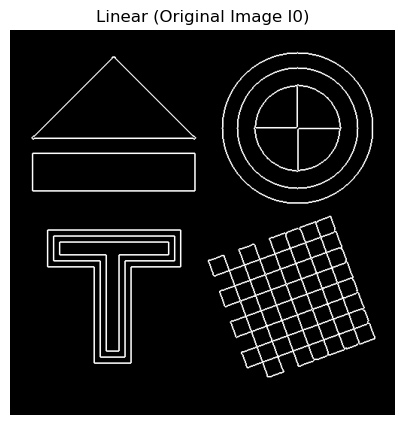

Nonlinear Edge Detection (Αρχική Εικόνα Ι0)


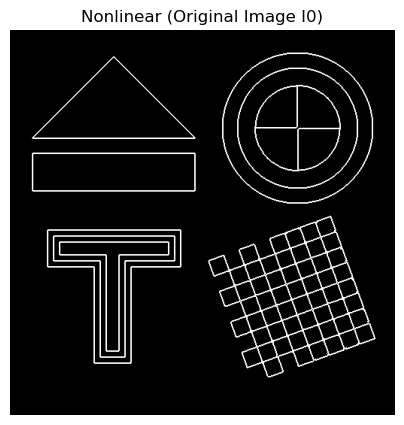

Linear Edge Detection (PSNR = 20 dB)


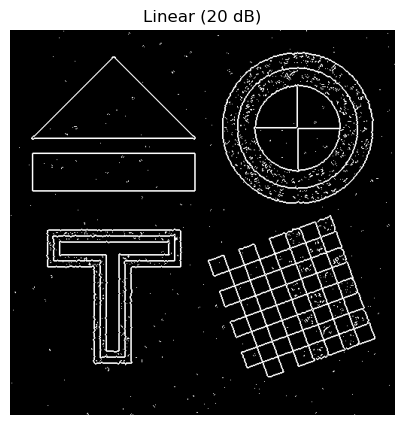

Nonlinear Edge Detection (PSNR = 20 dB)


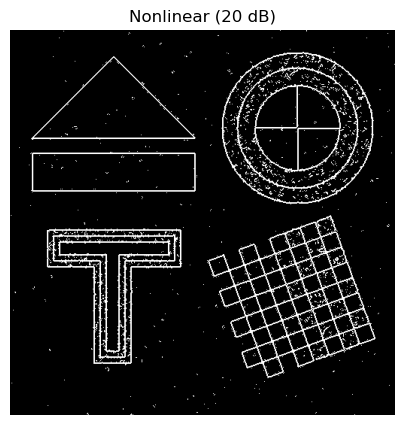

Linear Edge Detection (PSNR = 10 dB)


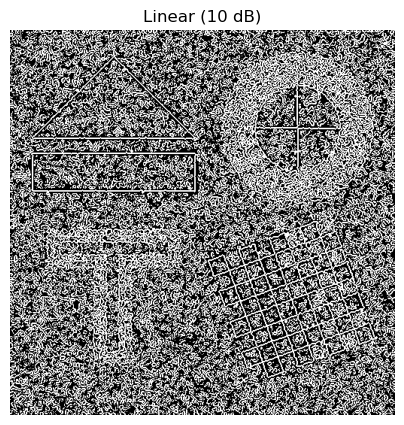

Nonlinear Edge Detection (PSNR = 10 dB)


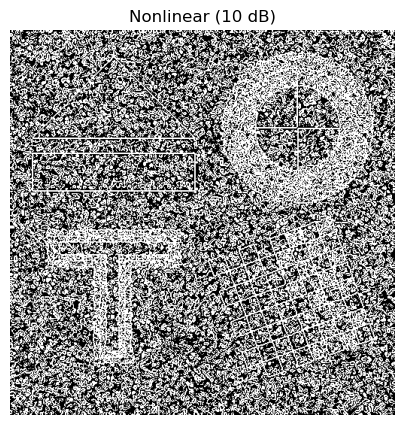

In [10]:
#1.2
import cv2
import numpy as np
import matplotlib.pyplot as plt

def EdgeDetect(image, sigma, theta_edge, method="linear"):
    # Μετατροπή εικόνας σε float32 αν δεν είναι ήδη
    image = image.astype(np.float32)
    # Υπολογισμός μεγέθους πυρήνα n
    n = int(np.ceil(3 * sigma) * 2 + 1)

    # 1.2.1 Δημιουργία Gaussian πυρήνα
    gauss_kernel_1d = cv2.getGaussianKernel(n, sigma).astype(np.float32)
    gauss_kernel_2d = gauss_kernel_1d @ gauss_kernel_1d.T  # Επέκταση σε 2D

    # 1.2.2 Εξομάλυνση της εικόνας
    smoothed = cv2.filter2D(image, -1, gauss_kernel_2d).astype(np.float32)

    if method == "linear":
        # Υπολογισμός Laplacian of Gaussian (LoG) πυρήνα απευθείας
        y, x = np.meshgrid(np.arange(-n//2 + 1, n//2 + 1), np.arange(-n//2 + 1, n//2 + 1))
        norm = x**2 + y**2
        LoG_kernel = ((norm - 2 * sigma**2) / (sigma**4)) * np.exp(-norm / (2 * sigma**2))
        LoG_kernel -= LoG_kernel.mean()  # Κανονικοποίηση

        # Μετατροπή LoG_kernel σε float32 και εφαρμογή φίλτρου
        LoG_kernel = LoG_kernel.astype(np.float32)
        L = cv2.filter2D(smoothed, -1, LoG_kernel).astype(np.float32)
    else:
        # Μη-γραμμική εκτίμηση της Laplacian μέσω μορφολογικών φίλτρων (dilation, erosion)
        B = np.array([[0, 1, 0],
              [1, 1, 1],
              [0, 1, 0]], dtype=np.uint8)

        dilated = cv2.dilate(smoothed, B).astype(np.float32)
        eroded = cv2.erode(smoothed, B).astype(np.float32)
        L = dilated + eroded - 2 * smoothed

    # Δημιουργία δυαδικής εικόνας προσήμου X
    X = (L >= 0).astype(np.float32)  

    # 1.2.3 Zerocrossings
    B = np.array([[0, 1, 0],
              [1, 1, 1],
              [0, 1, 0]], dtype=np.uint8)
    Y = cv2.dilate(X, B).astype(np.float32) - cv2.erode(X, B).astype(np.float32)

    # 1.2.4 Απόρριψη zerocrossings σε ομαλές περιοχές
    grad_x, grad_y = np.gradient(smoothed)  # Παραμένει float32
    grad_magnitude = np.sqrt(grad_x**2 + grad_y**2)
    max_grad = np.max(grad_magnitude)

    # Συνθήκη αποδοχής 
    D = (Y == 1) & (grad_magnitude > theta_edge * max_grad)

    # Επιστροφή αποτελέσματος σε float32 (με 0.0 και 255.0 για εμφάνιση)
    return D.astype(np.float32) * 255.0

sigma = 1.0
theta_edge = 0.1

edges1_linear = EdgeDetect(I0, sigma, theta_edge, "linear")
edges1_nonlinear = EdgeDetect(I0, sigma, theta_edge, "nonlinear")

edges2_linear = EdgeDetect(I_20dB, sigma, theta_edge, "linear")
edges2_nonlinear = EdgeDetect(I_20dB, sigma, theta_edge, "nonlinear")

edges3_linear = EdgeDetect(I_10dB, sigma, theta_edge, "linear")
edges3_nonlinear = EdgeDetect(I_10dB, sigma, theta_edge, "nonlinear")

# Εμφάνιση αποτελεσμάτων
def show_img(title, img):
    plt.figure(figsize=(5,5))
    plt.imshow(img.astype(np.uint8), cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

print("Linear Edge Detection (Αρχική Εικόνα Ι0)")
show_img("Linear (Original Image Ι0)", edges1_linear)

print("Nonlinear Edge Detection (Αρχική Εικόνα Ι0)")
show_img("Nonlinear (Original Image Ι0)", edges1_nonlinear)

print("Linear Edge Detection (PSNR = 20 dB)")
show_img("Linear (20 dB)", edges2_linear)

print("Nonlinear Edge Detection (PSNR = 20 dB)")
show_img("Nonlinear (20 dB)", edges2_nonlinear)

print("Linear Edge Detection (PSNR = 10 dB)")
show_img("Linear (10 dB)", edges3_linear)

print("Nonlinear Edge Detection (PSNR = 10 dB)")
show_img("Nonlinear (10 dB)", edges3_nonlinear)


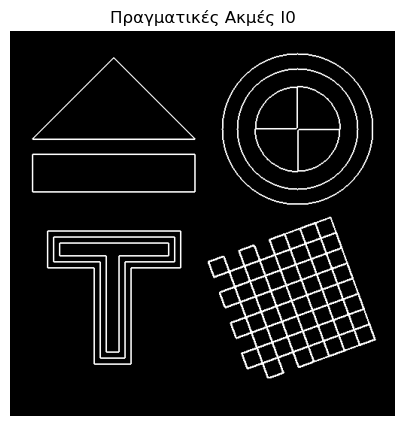

In [6]:
#1.3.1
import cv2
import numpy as np
import matplotlib.pyplot as plt

def true_edges(image, threshold=30):
    # Μετατροπή της εικόνας σε float32 για ακρίβεια στους υπολογισμούς
    image = image.astype(np.float32)

    # Ορισμός του B
    B = np.array([[0, 1, 0],
                  [1, 1, 1],
                  [0, 1, 0]], dtype=np.uint8)

    # Dilation και Erosion
    dilated = cv2.dilate(image, B)
    eroded = cv2.erode(image, B)

    # Υπολογισμός του Μ
    M = dilated - eroded

    # Κατωφλιοποίηση
    T = (M > threshold).astype(np.uint8) * 255  # Δυαδική εικόνα (0 και 255)

    return T

true_edge_image = true_edges(I0, 30)


# Εμφάνιση με matplotlib
plt.figure(figsize=(5, 5))
plt.imshow(true_edge_image, cmap='gray')
plt.title("Πραγματικές Ακμές I0")
plt.axis('off')
plt.show()


In [7]:
#1.3.2
def quality_metric(D, T):

    D_bin = (D > 0).astype(np.uint8)  # 1 όπου υπάρχει ανίχνευση
    T_bin = (T > 0).astype(np.uint8)  # 1 όπου υπάρχει αληθινή ακμή

    # Υπολογισμός |D ∩ T|
    intersection = np.logical_and(D_bin, T_bin).sum()

    # Υπολογισμός |D| (ανιχνευθείσες ακμές)
    D_count = D_bin.sum()

    # Υπολογισμός |T| (αληθινές ακμές)
    T_count = T_bin.sum()

    # Υπολογισμός Precision και Recall
    precision = intersection / D_count if D_count > 0 else 0
    recall = intersection / T_count if T_count > 0 else 0

    # Υπολογισμός C
    C = (precision + recall) / 2

    return C, precision, recall

C2, precision2, recall2 = quality_metric(edges2_linear, true_edge_image)
C3, precision3, recall3 = quality_metric(edges3_linear, true_edge_image)


print(f"Precision I0_20dB):", precision2)
print(f"Recall I0_20dB):", recall2)
print(f"C I0_20dB", C2)
print(f"Precision I0_10dB):", precision3)
print(f"Recall I0_10dB):", recall3)
print(f"C I0_10dB", C3)



Precision I0_20dB): 0.8149667142177841
Recall I0_20dB): 0.865648083843677
C I0_20dB 0.8403073990307306
Precision I0_10dB): 0.09987593568639205
Recall I0_10dB): 0.7573079108529579
C I0_10dB 0.428591923269675


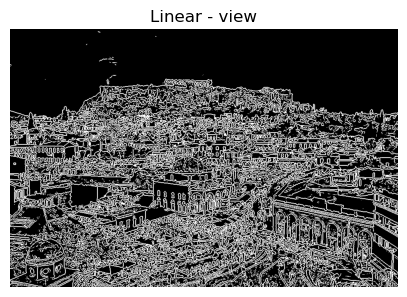

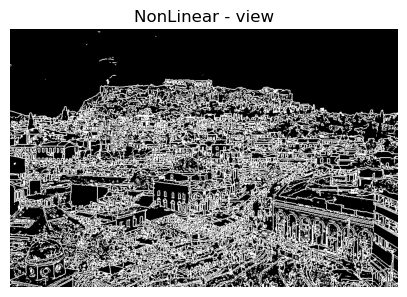

In [8]:
#1.4.1
view = cv2.imread("view.png", cv2.IMREAD_GRAYSCALE)
view_linear = EdgeDetect(view, sigma, theta_edge, "linear")
view_nonlinear = EdgeDetect(view, sigma, theta_edge, "nonlinear")
show_img("Linear - view", view_linear)
show_img("NonLinear - view", view_nonlinear)

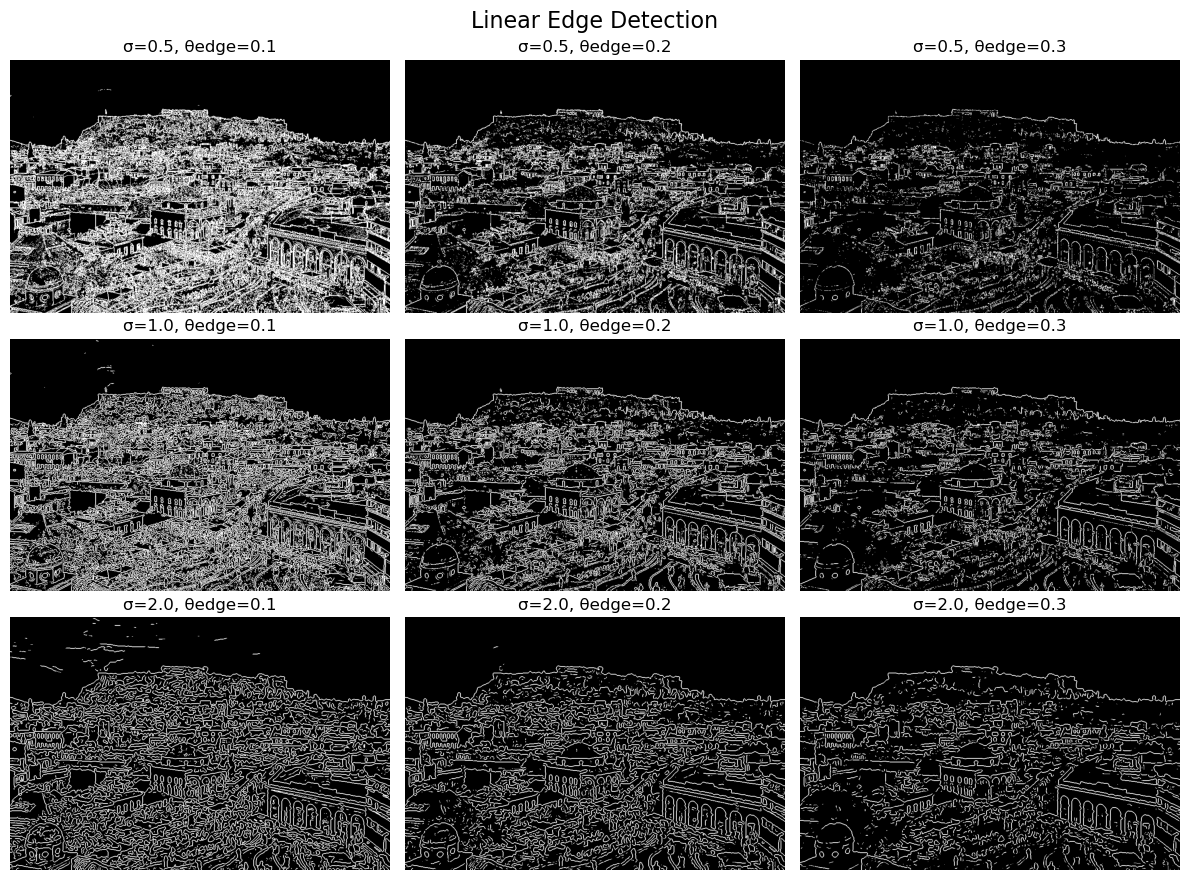

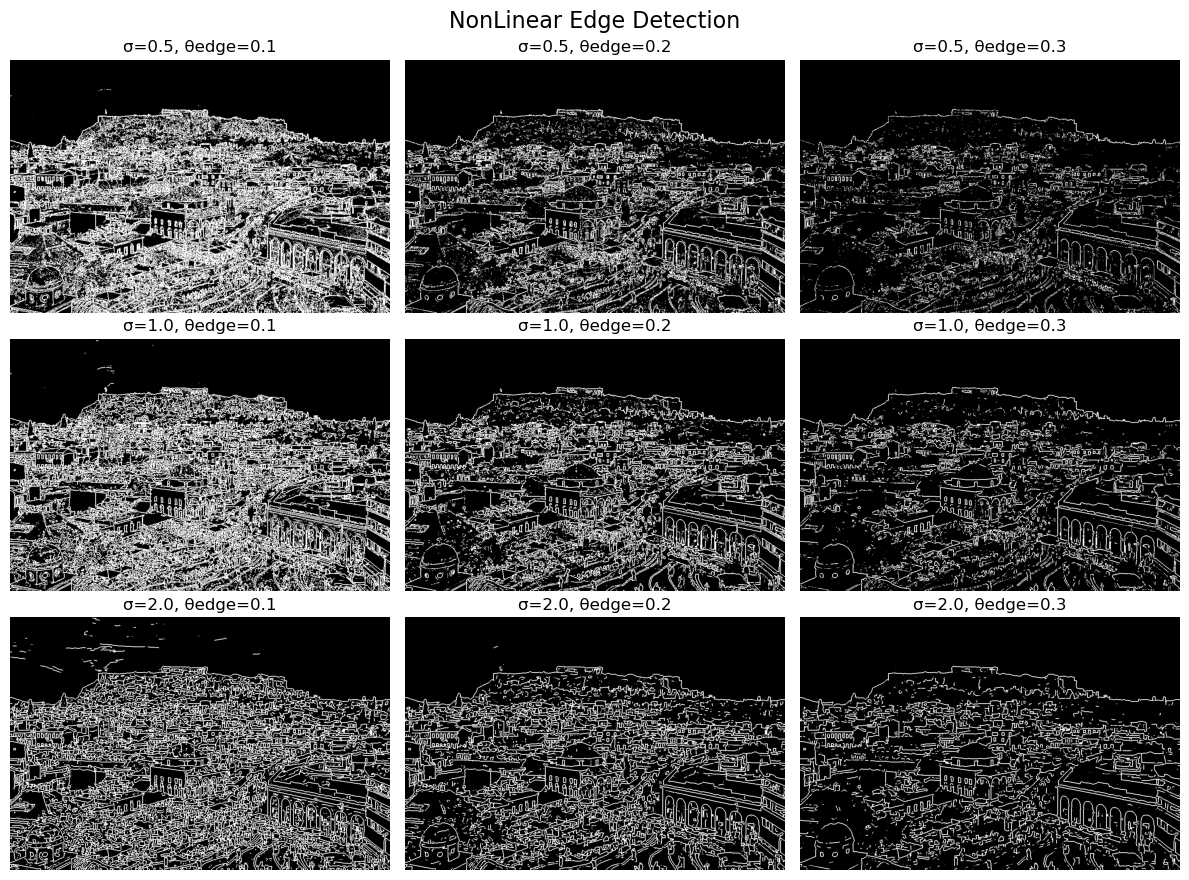

In [9]:
# 1.4.2
import cv2
import numpy as np
import matplotlib.pyplot as plt

view = cv2.imread("view.png", cv2.IMREAD_GRAYSCALE)

# Λίστες με τιμές για sigma και theta
sigma_values = [0.5, 1.0, 2.0]
theta_values = [0.1, 0.2, 0.3]

fig, axs = plt.subplots(len(sigma_values), len(theta_values), figsize=(12, 9))
fig.suptitle('Linear Edge Detection', fontsize=16)

for i, sigma in enumerate(sigma_values):
    for j, theta in enumerate(theta_values):
        edges = EdgeDetect(view, sigma, theta, "linear")
        axs[i, j].imshow(edges, cmap='gray')
        axs[i, j].set_title(f"σ={sigma}, θedge={theta}")
        axs[i, j].axis('off')

plt.tight_layout()
plt.show()

# nonlinear μέθοδος:
fig2, axs2 = plt.subplots(len(sigma_values), len(theta_values), figsize=(12, 9))
fig2.suptitle('NonLinear Edge Detection', fontsize=16)

for i, sigma in enumerate(sigma_values):
    for j, theta in enumerate(theta_values):
        edges = EdgeDetect(view, sigma, theta, "nonlinear")
        axs2[i, j].imshow(edges, cmap='gray')
        axs2[i, j].set_title(f"σ={sigma}, θedge={theta}")
        axs2[i, j].axis('off')

plt.tight_layout()
plt.show()


# Μέρος 2

J1


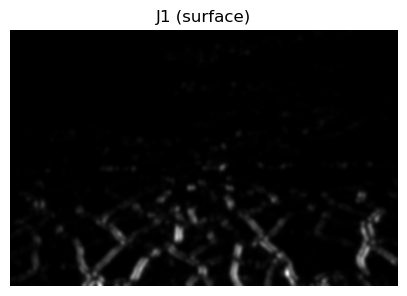

J2


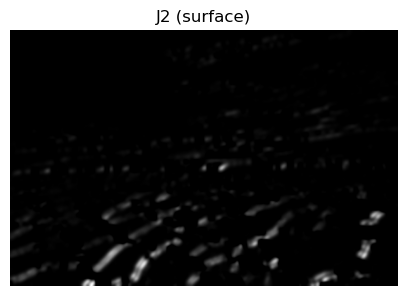

J3


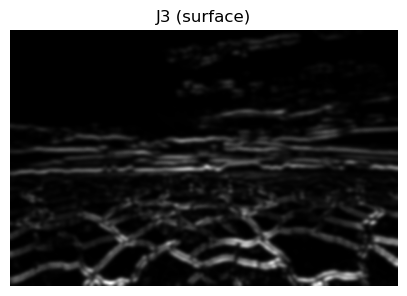

J1


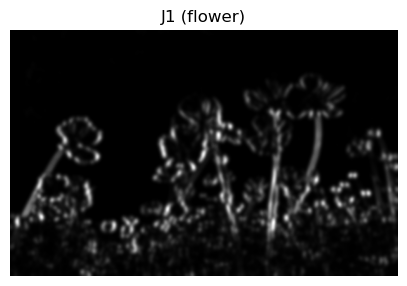

J2


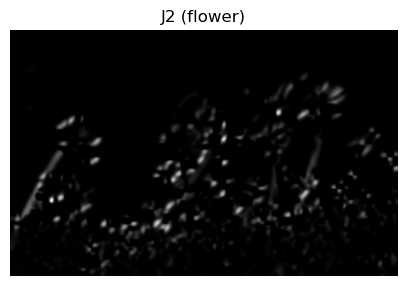

J3


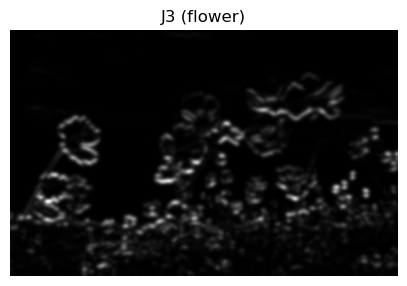

In [2]:
# 2.1.1
from scipy.ndimage import gaussian_filter
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Διαβάζουμε τις εικόνες σε γκρίζα κλίμακα
flower = cv2.imread("flowers.jpg", cv2.IMREAD_GRAYSCALE)
surface = cv2.imread("surface.png", cv2.IMREAD_GRAYSCALE)

def structure_tensor(image, sigma=2.0, rho=2.5):
    # Μετατροπή της εικόνας σε float32
    image = image.astype(np.float32)

    # Βήμα 1: Gaussian smoothing στην εικόνα I (Iσ = Gσ * I)
    I_sigma = gaussian_filter(image, sigma=sigma)

    # Βήμα 2: Υπολογισμός των παραγώγων (∂Iσ/∂x και ∂Iσ/∂y)
    Iy, Ix = np.gradient(I_sigma)

    # Βήμα 3: Υπολογισμός των στοιχείων J1, J2, J3
    J1 = gaussian_filter(Ix * Ix, sigma=rho)  # Gρ * (∂Iσ/∂x)^2
    J2 = gaussian_filter(Ix * Iy, sigma=rho)  # Gρ * (∂Iσ/∂x * ∂Iσ/∂y)
    J3 = gaussian_filter(Iy * Iy, sigma=rho)  # Gρ * (∂Iσ/∂y)^2

    return J1, J2, J3

def show_tensor(title, tensor):
    plt.figure(figsize=(5, 5))
    plt.imshow((tensor / np.max(tensor) * 255).astype(np.uint8), cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

# surface
J1_surf, J2_surf, J3_surf = structure_tensor(surface)
print("J1")
show_tensor("J1 (surface)", J1_surf)
print("J2")
show_tensor("J2 (surface)", J2_surf)
print("J3")
show_tensor("J3 (surface)", J3_surf)

# flower
J1_flower, J2_flower, J3_flower = structure_tensor(flower)
print("J1")
show_tensor("J1 (flower)", J1_flower)
print("J2")
show_tensor("J2 (flower)", J2_flower)
print("J3")
show_tensor("J3 (flower)", J3_flower)


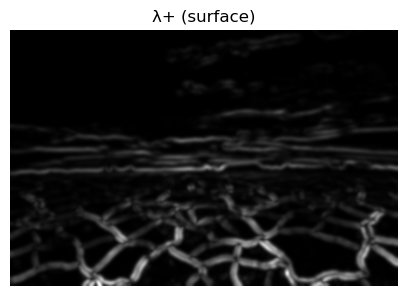

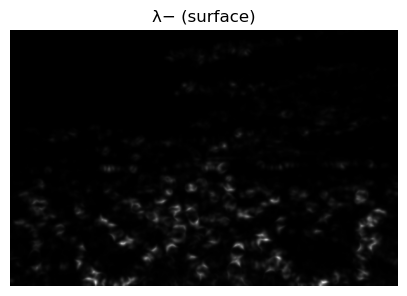

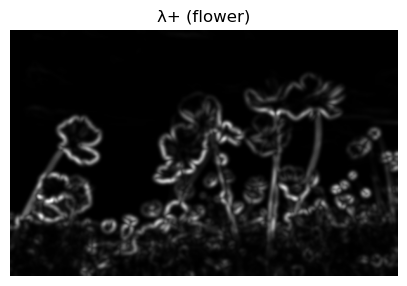

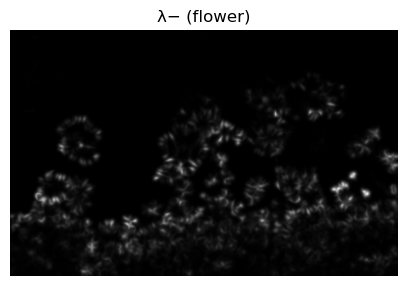

In [3]:
# 2.1.2
def compute_eigenvalues(J1, J2, J3):
    trace = J1 + J3
    determinant = (J1 * J3) - (J2 ** 2)
    discriminant = np.sqrt((J1 - J3) ** 2 + 4 * J2 ** 2)

    l_plus = 0.5 * (trace + discriminant)
    l_minus = 0.5 * (trace - discriminant)

    return l_plus, l_minus

# Υπολογισμός ιδιοτιμών
l_plus_surf, l_minus_surf = compute_eigenvalues(J1_surf, J2_surf, J3_surf)
l_plus_flower, l_minus_flower = compute_eigenvalues(J1_flower, J2_flower, J3_flower)

# Συνάρτηση εμφάνισης
def show_eigen(title, eig):
    plt.figure(figsize=(5, 5))
    plt.imshow((eig / np.max(eig) * 255).astype(np.uint8), cmap='gray')
    plt.title(title)
    plt.axis('off')
    plt.show()

# surface
show_eigen("λ+ (surface)", l_plus_surf)
show_eigen("λ− (surface)", l_minus_surf)

# flower
show_eigen("λ+ (flower)", l_plus_flower)
show_eigen("λ− (flower)", l_minus_flower)


In [1]:
def interest_points_visualization(I_, kp_data_, ax=None):
    '''
    Plot keypoints chosen by detectos on image.
    Args:
        I_: Image (if colored, make sure it is in RGB and not BGR).
        kp_data_: Nx3 array, as described in assignment.
        ax: Matplotlib axis to plot on (if None, a new Axes object is created).
    Returns:
        ax: Matplotlib axis where the image was plotted.
    '''
    try:
        I = np.array(I_)
        kp_data = np.array(kp_data_)
    except:
        print('Conversion to numpy arrays failed, check if the inputs (image and keypoints) are in the required format.')
        exit(2)

    try:
        assert(len(I.shape) == 2 or (len(I.shape) == 3 and I.shape[2] == 3))
    except AssertionError as e:
        print('interest_points_visualization: Image must be either a 2D matrix or a 3D matrix with the last dimension having size equal to 3.', file=sys.stderr)
        exit(2)

    try:
        assert(len(kp_data.shape) == 2 and kp_data.shape[1] == 3)
    except AssertionError as e:
        print('interest_points_visualization: kp_data must be a 2D matrix with 3 columns.', file=sys.stderr)
        exit(2)

    if ax is None:
        _, ax = plt.subplots()

    ax.set_aspect('equal')
    ax.imshow(I)
    ax.tick_params(bottom=False, left=False, labelbottom=False, labelleft=False)

    for i in range(len(kp_data)):
        x, y, sigma = kp_data[i]
        circ = Circle((x, y), 3*sigma, edgecolor='g', fill=False, linewidth=2)
        ax.add_patch(circ)

    return ax


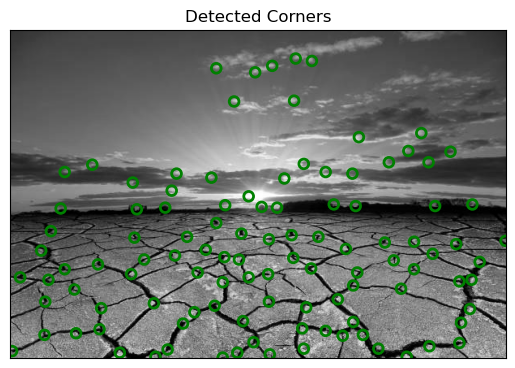

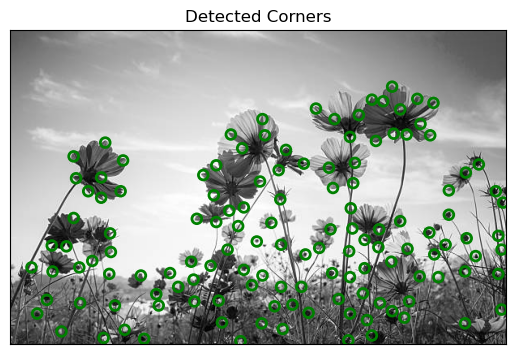

In [6]:
# 2.1.3
from matplotlib.patches import Circle

def disk_strel(n):
    '''
        Return a structural element, which is a disk of radius n.
    '''
    r = int(np.round(n))
    d = 2*r+1
    x = np.arange(d) - r
    y = np.arange(d) - r
    x, y = np.meshgrid(x, y)
    strel = x**2 + y**2 <= r**2
    return strel.astype(np.uint8)

def compute_cornerness(lambda_plus, lambda_minus, k=0.05):
    # Υπολογισμός του R(x, y)
    R = (lambda_minus * lambda_plus) - k * ((lambda_minus + lambda_plus) ** 2)
    return R

def detect_corners(R, sigma=2.0, theta_corn=0.005):
    # Δημιουργία δομικού στοιχείου δίσκου
    ns = int(np.ceil(3 * sigma) * 2 + 1)
    B_sq = disk_strel(ns)

    # (Σ1): Εντοπισμός τοπικών μεγίστων
    Cond1 = (R == cv2.dilate(R, B_sq))

    # (Σ2): Εφαρμογή κατωφλίου
    R_max = np.max(R)
    Cond2 = R > (theta_corn * R_max)

    # Τα σημεία είναι που ικανοποιούν και τις δύο συνθήκες
    corners = np.where(Cond1 & Cond2)

    return corners

# Υπολογισμός κριτηρίου γωνιότητας R
R_surf = compute_cornerness(l_plus_surf, l_minus_surf)
R_flower = compute_cornerness(l_plus_flower, l_minus_flower)

# Ανίχνευση γωνιών
corners_surf = detect_corners(R_surf)
corners_flower = detect_corners(R_flower)

surface_gray = surface.copy()
flower_gray = flower.copy()

# Σχεδίαση γωνιών στην εικόνα
sigma = 2.0
kp_data_surf = np.column_stack((corners_surf[1], corners_surf[0], np.full_like(corners_surf[0], sigma)))
kp_data_flower = np.column_stack((corners_flower[1], corners_flower[0], np.full_like(corners_flower[0], sigma)))

# Μετατροπή σε RGB αν είναι grayscale
if len(surface_gray.shape) == 2:
    surface_rgb = cv2.cvtColor(surface_gray, cv2.COLOR_GRAY2RGB)
else:
    surface_rgb = cv2.cvtColor(surface_gray, cv2.COLOR_BGR2RGB)

if len(flower_gray.shape) == 2:
    flower_rgb = cv2.cvtColor(flower_gray, cv2.COLOR_GRAY2RGB)
else:
    flower_rgb = cv2.cvtColor(flower_gray, cv2.COLOR_BGR2RGB)

# Εμφάνιση αποτελεσμάτων
interest_points_visualization(surface_rgb, kp_data_surf)
plt.title("Detected Corners")
plt.show()

interest_points_visualization(flower_rgb, kp_data_flower)
plt.title("Detected Corners")
plt.show()

In [7]:
# 2.2.1
def multi_scale_corner_detection(image, sigma0=2.0, rho0=2.5, s=1.5, N=4, k=0.05, theta_corn=0.005):
    """
    Εντοπισμός γωνιών για πολλαπλές κλίμακες με Harris 
    
    """
    import numpy as np
    import cv2
    from scipy.ndimage import gaussian_filter

    def structure_tensor(I, sigma, rho):
        I = I.astype(np.float32)
        I_sigma = gaussian_filter(I, sigma=sigma)
        Ix = cv2.Sobel(I_sigma, cv2.CV_32F, 1, 0, ksize=3)
        Iy = cv2.Sobel(I_sigma, cv2.CV_32F, 0, 1, ksize=3)
        J1 = gaussian_filter(Ix * Ix, sigma=rho)
        J2 = gaussian_filter(Ix * Iy, sigma=rho)
        J3 = gaussian_filter(Iy * Iy, sigma=rho)
        return J1, J2, J3

    def compute_cornerness(l_plus, l_minus, k):
        return (l_minus * l_plus) - k * ((l_minus + l_plus) ** 2)

    def compute_eigenvalues(J1, J2, J3):
        trace = J1 + J3
        disc = np.sqrt((J1 - J3)**2 + 4 * J2**2)
        l_plus = 0.5 * (trace + disc)
        l_minus = 0.5 * (trace - disc)
        return l_plus, l_minus

    def detect_corners(R, sigma, theta_corn):
        ns = int(np.ceil(3 * sigma) * 2 + 1)
        strel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ns, ns))
        Cond1 = (R == cv2.dilate(R, strel))
        Cond2 = R > (theta_corn * np.max(R))
        return np.where(Cond1 & Cond2)

    all_points = []
    for n in range(N):
        sigma_n = s**n * sigma0
        rho_n = s**n * rho0

        J1, J2, J3 = structure_tensor(image, sigma_n, rho_n)
        l_plus, l_minus = compute_eigenvalues(J1, J2, J3)
        R = compute_cornerness(l_plus, l_minus, k)
        corners = detect_corners(R, sigma_n, theta_corn)

        for y, x in zip(*corners):
            all_points.append((x, y, sigma_n))

    return all_points  


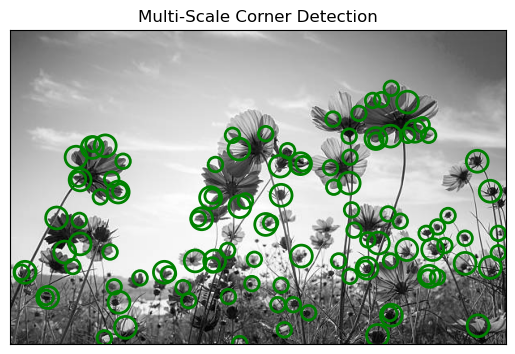

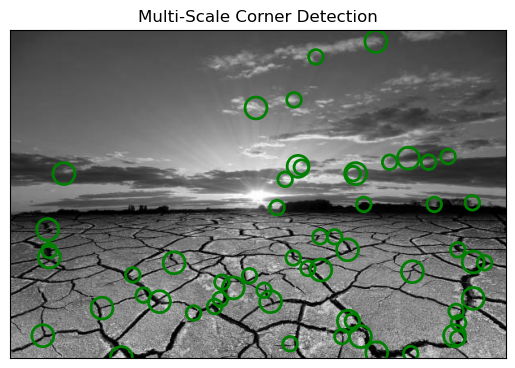

In [8]:
#2.2.2.
def automatic_scale_selection(image, detected_points, sigma0=2.0, s=1.5, N=4):
    """
    Επιλογή χαρακτηριστικής κλίμακας με βάση τοπικά μέγιστα στη LoG
    
    """
    import numpy as np
    from scipy.ndimage import gaussian_laplace

    def compute_log(I, sigma):
        log = gaussian_laplace(I.astype(np.float32), sigma)
        return np.abs(log * (sigma ** 2))

    # Προετοιμασία κλιμάκων και LoG αποκρίσεων
    scales = [s**i * sigma0 for i in range(N)]
    log_responses = [compute_log(image, sigma) for sigma in scales]

    keypoints = []
    for i in range(1, N - 1):
        prev_log = log_responses[i - 1]
        curr_log = log_responses[i]
        next_log = log_responses[i + 1]

        local_max = (curr_log > prev_log) & (curr_log > next_log)

        # Κρατάμε μόνο τα σημεία της σκάλας i που είναι max στη LoG
        for x, y, sigma in filter(lambda pt: abs(pt[2] - scales[i]) < 1e-4, detected_points):
            if local_max[int(y), int(x)]:
                keypoints.append([x, y, sigma])

    return np.array(keypoints, dtype=np.float32)  
# Φόρτωση εικόνων
flower = cv2.imread("flowers.jpg", cv2.IMREAD_GRAYSCALE)
surface = cv2.imread("surface.png", cv2.IMREAD_GRAYSCALE)

# 2.2.1: Ανίχνευση πολυκλιμακωτών γωνιών
detected_points_flower = multi_scale_corner_detection(flower)
detected_points_surface = multi_scale_corner_detection(surface)

# 2.2.2: Επιλογή χαρακτηριστικής κλίμακας (LoG filtering)
kp_data_flower = automatic_scale_selection(flower, detected_points_flower)
kp_data_surface = automatic_scale_selection(surface, detected_points_surface)

# Οπτικοποίηση
flower_gray = cv2.cvtColor(flower, cv2.COLOR_GRAY2RGB)
interest_points_visualization(flower_gray, kp_data_flower)
plt.title("Multi-Scale Corner Detection")
plt.show()
surface_gray = cv2.cvtColor(surface, cv2.COLOR_GRAY2RGB)
interest_points_visualization(surface_gray, kp_data_surface)
plt.title("Multi-Scale Corner Detection")
plt.show()


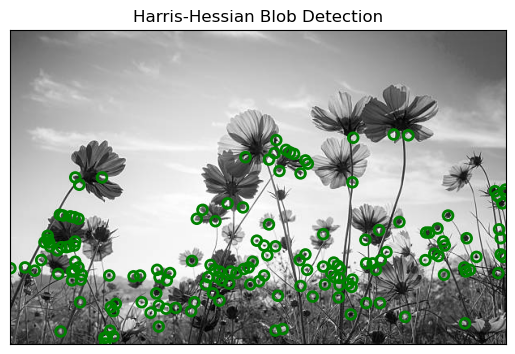

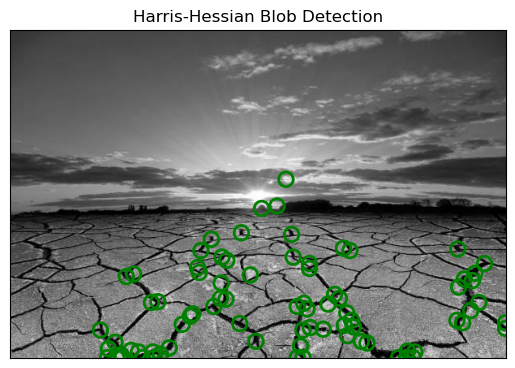

In [47]:
#2.3.1.
#2.3.2.
import numpy as np
import cv2
from scipy.ndimage import gaussian_filter, maximum_filter

def hessianDetector(image, sigma, theta_blob):
    """
    Μονοκλιμακωτή ανίχνευση blobs με βάση την ορίζουσα Hessian.

    """
    image = image.astype(np.float32)
    Lxx = gaussian_filter(image, sigma=sigma, order=(2, 0))
    Lyy = gaussian_filter(image, sigma=sigma, order=(0, 2))
    Lxy = gaussian_filter(image, sigma=sigma, order=(1, 1))

    # Υπολογισμός της ορίζουσας
    R = Lxx * Lyy - Lxy**2

    # Τοπικά μέγιστα
    local_max = (R == maximum_filter(R, size=3))

    # Κατώφλι
    R_max = np.max(R)
    Cond = (R > theta_blob * R_max) & local_max

    # Συντεταγμένες blobs
    y_coords, x_coords = np.where(Cond)
    sigmas = np.full_like(x_coords, sigma, dtype=np.float32)

    # Σύνθεση αποτελέσματος
    kp_data = np.stack((x_coords, y_coords, sigmas), axis=-1)  
    return kp_data

flower = cv2.imread('flowers.jpg', cv2.IMREAD_GRAYSCALE)
kp_flower = hessianDetector(flower, sigma=2.0, theta_blob=0.23)

flower_rgb = cv2.cvtColor(flower, cv2.COLOR_GRAY2RGB)
interest_points_visualization(flower_rgb, kp_flower)
plt.title("Harris-Hessian Blob Detection")
plt.show()

surface = cv2.imread('surface.png', cv2.IMREAD_GRAYSCALE)
kp_surface = hessianDetector(surface, sigma=3.0, theta_blob=0.2)

surface_rgb = cv2.cvtColor(surface, cv2.COLOR_GRAY2RGB)
interest_points_visualization(surface_rgb, kp_surface)
plt.title("Harris-Hessian Blob Detection")
plt.show()


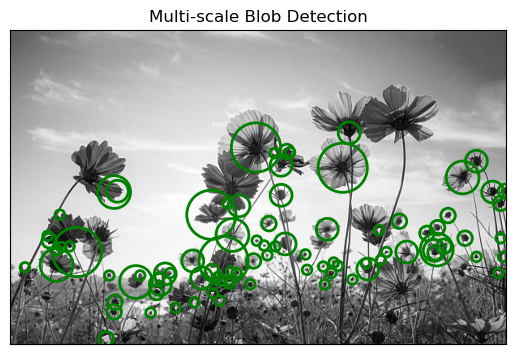

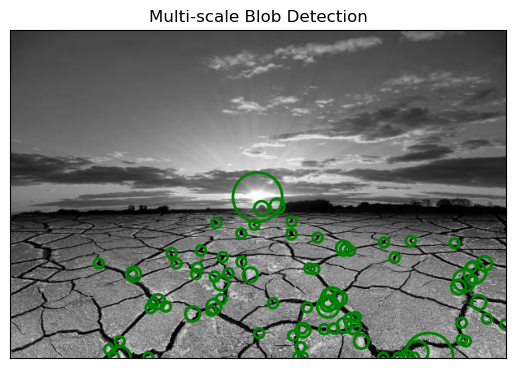

In [43]:
#2.4.1.
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_laplace, maximum_filter
from matplotlib.patches import Circle

import numpy as np
import cv2
from scipy.ndimage import gaussian_filter, maximum_filter

def hessianLaplaceDetector(image, sigma0=2.0, s=1.5, N=5, theta_blob=0.2):
    """
    Hessian-Laplace ανιχνευτής

    """
    image = image.astype(np.float32)
    h, w = image.shape
    scales = [sigma0 * (s ** i) for i in range(N)]

    # Υπολογισμός det(H) και LoG
    detH_stack = np.zeros((N, h, w))
    log_stack = np.zeros((N, h, w))

    for i, sigma in enumerate(scales):
        Lxx = gaussian_filter(image, sigma=sigma, order=(2, 0))
        Lyy = gaussian_filter(image, sigma=sigma, order=(0, 2))
        Lxy = gaussian_filter(image, sigma=sigma, order=(1, 1))
        detH = (Lxx * Lyy - Lxy**2) * sigma**4  
        LoG = np.abs(gaussian_laplace(image, sigma=sigma)) * sigma**2

        detH_stack[i] = detH
        log_stack[i] = LoG

    # Τοπικά μέγιστα στο det(H)
    detH_max = maximum_filter(detH_stack, size=(3, 3, 3))
    local_max_detH = (detH_stack == detH_max)
    valid_detH = detH_stack > (theta_blob * np.max(detH_stack))
    mask_detH = local_max_detH & valid_detH

    # Τοπικά μέγιστα στο LoG για επιλογή κλίμακας
    log_max = maximum_filter(log_stack, size=(3, 3, 3))
    local_max_log = (log_stack == log_max)

    # Mέγιστο και σε det(H) και σε LoG
    final_mask = mask_detH & local_max_log

    keypoints = []
    for i, sigma in enumerate(scales):
        y_coords, x_coords = np.where(final_mask[i])
        for y, x in zip(y_coords, x_coords):
            keypoints.append([x, y, sigma])

    return np.array(keypoints, dtype=np.float32)

flower = cv2.imread('flowers.jpg', cv2.IMREAD_GRAYSCALE)
keypoints_flower = hessianLaplaceDetector(flower, sigma0=2.0, s=1.5, N=5, theta_blob=0.3)

interest_points_visualization(flower_rgb, keypoints_flower)
plt.title("Multi-scale Blob Detection")
plt.show()

surface = cv2.imread('surface.png', cv2.IMREAD_GRAYSCALE)
keypoints_surface = hessianLaplaceDetector(surface,  sigma0=2.0, s=1.5, N=6, theta_blob=0.2)

interest_points_visualization(surface_rgb, keypoints_surface)
plt.title("Multi-scale Blob Detection")
plt.show()


# Μέρος 3

Ορισμένοι ανιχνευτές, η υλοποίηση των οποίων έγινε τμηματικά στα ανωτέρω ερωτήματα, δίνονται και εδω συνολικά (σε μια ενιαία συνάρτηση) για ευκολία.

In [53]:
# 3.1.
# Harris Corner Detector (Ανίχνευση γωνιών σε μία κλίμακα)
# 1/4 
import numpy as np
import cv2
from scipy.ndimage import gaussian_filter

def disk_strel(n):
    '''
        Return a structural element, which is a disk of radius n.
    '''
    r = int(np.round(n))
    d = 2*r+1
    x = np.arange(d) - r
    y = np.arange(d) - r
    x, y = np.meshgrid(x, y)
    strel = x**2 + y**2 <= r**2
    return strel.astype(np.uint8)

def harrisDetector(image, sigma=2.0, rho=2.5, k=0.05, theta_corn=0.005):
    """
    Υλοποιεί τον Harris corner detector και επιστρέφει τα σημεία ενδιαφέροντος σε μορφή Nx3 (x, y, σ)
    """
    # Ομαλοποίηση
    image = image.astype(np.float32)
    I_sigma = gaussian_filter(image, sigma=sigma)

    # Παραγωγίσεις
    Ix = cv2.Sobel(I_sigma, cv2.CV_32F, 1, 0, ksize=3)
    Iy = cv2.Sobel(I_sigma, cv2.CV_32F, 0, 1, ksize=3)

    # Στοιχεία δομικού τανυστή
    J1 = gaussian_filter(Ix * Ix, sigma=rho)
    J2 = gaussian_filter(Ix * Iy, sigma=rho)
    J3 = gaussian_filter(Iy * Iy, sigma=rho)

    # Ιδιοτιμές
    trace = J1 + J3
    determinant = (J1 * J3) - (J2 ** 2)
    discriminant = np.sqrt((J1 - J3) ** 2 + 4 * J2 ** 2)
    lambda_plus = 0.5 * (trace + discriminant)
    lambda_minus = 0.5 * (trace - discriminant)

    # Κριτήριο γωνιότητας
    R = (lambda_minus * lambda_plus) - k * ((lambda_minus + lambda_plus) ** 2)

    # Εντοπισμός γωνιών
    ns = int(np.ceil(3 * sigma) * 2 + 1)
    B_sq = disk_strel(ns)

    Cond1 = (R == cv2.dilate(R, B_sq))  # τοπικά μέγιστα
    Cond2 = R > (theta_corn * np.max(R))  # κατώφλι

    corners = np.where(Cond1 & Cond2)
    x_coords, y_coords = corners[1], corners[0]
    sigmas = np.full_like(x_coords, sigma, dtype=np.float32)

    kp_data = np.stack((x_coords, y_coords, sigmas), axis=-1)  # Nx3

    return kp_data


In [54]:
# 3.1.
# matching evaluation
# 1/4 (corner detection)
import cv25_lab1_part3_utils as p3

detect_fun = lambda I: harrisDetector(I, 2, 2.5, 0.05, 0.005)
desc_fun_surf = lambda I, kp: p3.featuresSURF(I, kp)
desc_fun_hog = lambda I, kp: p3.featuresHOG(I, kp)

# Εκτέλεση matching evaluation
avg_scale_errors_surf, avg_theta_errors_surf = p3.matching_evaluation(detect_fun, desc_fun_surf)
avg_scale_errors_hog, avg_theta_errors_hog = p3.matching_evaluation(detect_fun, desc_fun_hog)

# Εμφάνιση αποτελεσμάτων
print("Scale Error (SURF):", avg_scale_errors_surf)
print("Theta Error (SURF):", avg_theta_errors_surf)
print("Scale Error (HOG):", avg_scale_errors_hog)
print("Theta Error (HOG):", avg_theta_errors_hog)


Scale Error (SURF): [0.001359201771117731, 0.002032994773505007, 0.1283720208640088]
Theta Error (SURF): [0.18839426790984024, 0.13399286249121575, 8.052187178781779]
Scale Error (HOG): [0.15369843056773413, 0.18492274838354913, 0.30223481925274104]
Theta Error (HOG): [13.115891085105389, 17.33173518972428, 27.848895268885652]


In [56]:
# 3.1.
# Harris Laplacian (Πολυκλιμακωτή Ανίχνευση Γωνιών)
# 2/4
def harrisLaplace(image, sigma0=2.0, rho0=2.5, k=0.05, theta_corn=0.005, s=1.5, N=4):
    def structure_tensor(image, sigma, rho):
        image = image.astype(np.float32)
        I_sigma = gaussian_filter(image, sigma=sigma)
        Ix = cv2.Sobel(I_sigma, cv2.CV_32F, 1, 0, ksize=3)
        Iy = cv2.Sobel(I_sigma, cv2.CV_32F, 0, 1, ksize=3)
        J1 = gaussian_filter(Ix * Ix, sigma=rho)
        J2 = gaussian_filter(Ix * Iy, sigma=rho)
        J3 = gaussian_filter(Iy * Iy, sigma=rho)
        return J1, J2, J3

    def compute_eigenvalues(J1, J2, J3):
        trace = J1 + J3
        discriminant = np.sqrt((J1 - J3) ** 2 + 4 * J2 ** 2)
        l_plus = 0.5 * (trace + discriminant)
        l_minus = 0.5 * (trace - discriminant)
        return l_plus, l_minus

    def compute_cornerness(lambda_plus, lambda_minus, k):
        return (lambda_minus * lambda_plus) - k * ((lambda_minus + lambda_plus) ** 2)

    def detect_corners(R, sigma, theta_corn):
        ns = int(np.ceil(3 * sigma) * 2 + 1)
        B_sq = np.uint8(cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (ns, ns)))
        Cond1 = (R == cv2.dilate(R, B_sq))
        Cond2 = R > (theta_corn * np.max(R))
        return np.where(Cond1 & Cond2)

    def compute_log(image, sigma):
        log = gaussian_laplace(image.astype(np.float32), sigma)
        return np.abs(log * (sigma ** 2))

    # Harris detection σε N κλίμακες
    all_corners = []
    for n in range(N):
        sigma_n = (s ** n) * sigma0
        rho_n = (s ** n) * rho0
        J1, J2, J3 = structure_tensor(image, sigma_n, rho_n)
        l_plus, l_minus = compute_eigenvalues(J1, J2, J3)
        R = compute_cornerness(l_plus, l_minus, k)
        corners = detect_corners(R, sigma_n, theta_corn)
        all_corners.append((corners, sigma_n))

    # Υπολογισμός LoG για κάθε κλίμακα
    log_responses = [compute_log(image, (s ** i) * sigma0) for i in range(N)]

    # Επιλογή χαρακτηριστικής κλίμακας
    best_points = []
    for i in range(1, N - 1):
        curr_log = log_responses[i]
        prev_log = log_responses[i - 1]
        next_log = log_responses[i + 1]
        local_max = (curr_log > prev_log) & (curr_log > next_log)

        corners, sigma_n = all_corners[i]
        for y, x in zip(*corners):
            if local_max[y, x]:
                best_points.append([x, y, sigma_n])

    return np.array(best_points, dtype=np.float32)

In [58]:
# 3.1.
# matching evaluation
# 2/4 (multi-scale corner detection)
import cv25_lab1_part3_utils as p3

detect_fun = lambda I: harrisLaplace(I, sigma0=2, rho0=2.5, k=0.05, theta_corn=0.005, s=1.5, N=4)
desc_fun_surf = lambda I, kp: p3.featuresSURF(I, kp)
desc_fun_hog = lambda I, kp: p3.featuresHOG(I, kp)

# Εκτέλεση matching evaluation
avg_scale_errors_surf, avg_theta_errors_surf = p3.matching_evaluation(detect_fun, desc_fun_surf)
avg_scale_errors_hog, avg_theta_errors_hog = p3.matching_evaluation(detect_fun, desc_fun_hog)

# Εμφάνιση αποτελεσμάτων
print("Scale Error (SURF):", avg_scale_errors_surf)
print("Theta Error (SURF):", avg_theta_errors_surf)
print("Scale Error (HOG):", avg_scale_errors_hog)
print("Theta Error (HOG):", avg_theta_errors_hog)


Scale Error (SURF): [0.0015710242653322706, 0.003011451015731911, 0.0029774126362699556]
Theta Error (SURF): [0.15204849703349352, 0.14944586018735703, 0.23026182987838634]
Scale Error (HOG): [0.079634400316709, 0.34563321012068826, 1.0320066646456498]
Theta Error (HOG): [9.17770339335725, 31.625079047528935, 10.796125957530677]


In [50]:
# matching evaluation
# 3/4 (blob detection)
import cv2
import cv25_lab1_part3_utils as p3

detect_fun = lambda I: hessianDetector(I, sigma=2.0, theta_blob=0.2)


desc_fun_surf = lambda I, kp: p3.featuresSURF(I, kp)
desc_fun_hog = lambda I, kp: p3.featuresHOG(I, kp)

# Εκτέλεση matching evaluation
avg_scale_errors_surf, avg_theta_errors_surf = p3.matching_evaluation(detect_fun, desc_fun_surf)
avg_scale_errors_hog, avg_theta_errors_hog = p3.matching_evaluation(detect_fun, desc_fun_hog)

# Εμφάνιση αποτελεσμάτων
print("Scale Error (SURF):", avg_scale_errors_surf)
print("Theta Error (SURF):", avg_theta_errors_surf)
print("Scale Error (HOG):", avg_scale_errors_hog)
print("Theta Error (HOG):", avg_theta_errors_hog)


Scale Error (SURF): [0.002674487763254454, 0.8067166112413943, 0.008287623107142454]
Theta Error (SURF): [0.23134488278573198, 24.0027025375967, 1.6016171688214573]
Scale Error (HOG): [0.20505640392810276, 0.7835129689324392, 0.6848190223600089]
Theta Error (HOG): [15.834117357633192, 36.602204991487405, 27.164485266280955]


In [45]:
# 3.1.
# matching evaluation
# 4/4 (multi-scale blob detection)
import cv25_lab1_part3_utils as p3

detect_fun = lambda I: hessianLaplaceDetector(I, sigma0=2.0, s=1.5, N=4, theta_blob=0.2)
desc_fun_surf = lambda I, kp: p3.featuresSURF(I, kp)
desc_fun_hog = lambda I, kp: p3.featuresHOG(I, kp)

# Εκτέλεση matching evaluation
avg_scale_errors_surf, avg_theta_errors_surf = p3.matching_evaluation(detect_fun, desc_fun_surf)
avg_scale_errors_hog, avg_theta_errors_hog = p3.matching_evaluation(detect_fun, desc_fun_hog)

# Εμφάνιση αποτελεσμάτων
print("Scale Error (SURF):", avg_scale_errors_surf)
print("Theta Error (SURF):", avg_theta_errors_surf)
print("Scale Error (HOG):", avg_scale_errors_hog)
print("Theta Error (HOG):", avg_theta_errors_hog)

Scale Error (SURF): [0.0018382807697423626, 0.3500684514331008, 0.005850431137085873]
Theta Error (SURF): [0.12465566795190101, 10.958232269502448, 2.3084203587909475]
Scale Error (HOG): [0.19965114227728345, 0.5206529546920432, 1.451772871403861]
Theta Error (HOG): [13.04478641578011, 36.33331713632809, 21.89489911220184]


In [55]:
# 3.2.1
# Hessian Laplace (blobs)
import cv25_lab1_part3_utils as p3

# Define the detector & descriptors
detect_fun = lambda I: hessianLaplaceDetector(I, sigma0=2.0, s=1.5, N=4, theta_blob=0.2)
desc_fun_surf = lambda I, kp: p3.featuresSURF(I, kp)
desc_fun_hog = lambda I, kp: p3.featuresHOG(I, kp)

# Extract features 
feats_hessian_surf = p3.FeatureExtraction(detect_fun, desc_fun_surf, saveFile='feats_hessian_surf.mat')
feats_hessian_hog = p3.FeatureExtraction(detect_fun, desc_fun_hog, saveFile='feats_hessian_hog.mat')


Time for feature extraction: 24.544
Time for feature extraction: 30.488


In [57]:
# 3.2.1
# Harris Laplace (corners)
import cv25_lab1_part3_utils as p3

# Define the detector & descriptor
detect_fun = lambda I: harrisLaplace(I, sigma0=2.0, rho0=2.5, k=0.05, theta_corn=0.005, s=1.5, N=4)
desc_fun_surf = lambda I, kp: p3.featuresSURF(I, kp)
desc_fun_hog= lambda I, kp: p3.featuresHOG(I, kp)

# Extract features 
feats_harris_surf = p3.FeatureExtraction(detect_fun, desc_fun_surf, saveFile='feats_harris_surf.mat')
feats_harris_hog = p3.FeatureExtraction(detect_fun, desc_fun_hog, saveFile='feats_harris_hog.mat')

Time for feature extraction: 27.601
Time for feature extraction: 31.278


In [59]:
# 3.2.2 
accs = []

for k in range(5):  # 5-fold cross-validation
    
    data_train_HS, label_train_HS, data_test_HS, label_test_HS = p3.createTrainTest(feats_harris_surf, k)

    # Harris + HOG
    data_train_HH, label_train_HH, data_test_HH, label_test_HH = p3.createTrainTest(feats_harris_hog, k)

    # Hessian + SURF
    data_train_HeS, label_train_HeS, data_test_HeS, label_test_HeS = p3.createTrainTest(feats_hessian_surf, k)

    # Hessian + HOG
    data_train_HeH, label_train_HeH, data_test_HeH, label_test_HeH = p3.createTrainTest(feats_hessian_hog, k)

    # Έλεγχος μεγεθών
    print("\n--- Διαχωρισμός Train/Test ---")
    print(f"Harris + SURF:    Train = {len(label_train_HS)}, Test = {len(label_test_HS)}")
    print(f"Harris + HOG:     Train = {len(label_train_HH)}, Test = {len(label_test_HH)}")
    print(f"Hessian + SURF:   Train = {len(label_train_HeS)}, Test = {len(label_test_HeS)}")
    print(f"Hessian + HOG:    Train = {len(label_train_HeH)}, Test = {len(label_test_HeH)}")


--- Διαχωρισμός Train/Test ---
Harris + SURF:    Train = 337, Test = 145
Harris + HOG:     Train = 337, Test = 145
Hessian + SURF:   Train = 337, Test = 145
Hessian + HOG:    Train = 337, Test = 145

--- Διαχωρισμός Train/Test ---
Harris + SURF:    Train = 337, Test = 145
Harris + HOG:     Train = 337, Test = 145
Hessian + SURF:   Train = 337, Test = 145
Hessian + HOG:    Train = 337, Test = 145

--- Διαχωρισμός Train/Test ---
Harris + SURF:    Train = 337, Test = 145
Harris + HOG:     Train = 337, Test = 145
Hessian + SURF:   Train = 337, Test = 145
Hessian + HOG:    Train = 337, Test = 145

--- Διαχωρισμός Train/Test ---
Harris + SURF:    Train = 337, Test = 145
Harris + HOG:     Train = 337, Test = 145
Hessian + SURF:   Train = 337, Test = 145
Hessian + HOG:    Train = 337, Test = 145

--- Διαχωρισμός Train/Test ---
Harris + SURF:    Train = 337, Test = 145
Harris + HOG:     Train = 337, Test = 145
Hessian + SURF:   Train = 337, Test = 145
Hessian + HOG:    Train = 337, Test = 145


In [60]:
# 3.2.3 (bonus)

from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.utils import shuffle
import numpy as np

# Συνάρτηση για μετατροπή descriptors σε histograms
def descriptors_to_histograms(data, kmeans):
    histograms = []
    for descriptors in data:
        if descriptors is None or len(descriptors) == 0:
            hist = np.zeros(kmeans.n_clusters)
        else:
            idxs = kmeans.predict(descriptors)
            hist, _ = np.histogram(idxs, bins=np.arange(kmeans.n_clusters + 1))
        hist = normalize(hist.reshape(1, -1), norm='l2')
        histograms.append(hist.flatten())
    return np.array(histograms)

# Συνάρτηση δημιουργίας BoVW
def build_BoVW(data_train, data_test, K=1000, name="BoVW"):
    print(f"\n Δημιουργία BoVW ({name}) με {K} οπτικές λέξεις")
    
    # Συνένωση όλων των descriptors από το train set
    all_descriptors = np.vstack(data_train)
    
    # Υποδειγματοληψία
    all_descriptors = shuffle(all_descriptors, random_state=42)
    sampled_descriptors = all_descriptors[:len(all_descriptors) // 2]
    
    # Εκπαίδευση KMeans (οπτικό λεξικό)
    kmeans = KMeans(n_clusters=K, random_state=42, n_init=10, max_iter=300)
    kmeans.fit(sampled_descriptors)
    
    # Μετατροπή σε BoVW histograms
    BoVW_train = descriptors_to_histograms(data_train, kmeans)
    BoVW_test  = descriptors_to_histograms(data_test, kmeans)
    
    print(f" BoVW ({name}) ολοκληρώθηκε.\n")
    return BoVW_train, BoVW_test

# BoVW histograms
BoVW_train_HH, BoVW_test_HH = build_BoVW(data_train_HH, data_test_HH, K=1000, name="Harris + HOG")
BoVW_train_HS, BoVW_test_HS = build_BoVW(data_train_HS, data_test_HS, name="Harris + SURF")
BoVW_train_HeS, BoVW_test_HeS = build_BoVW(data_train_HeS, data_test_HeS, name="Hessian + SURF")
BoVW_train_HeH, BoVW_test_HeH = build_BoVW(data_train_HeH, data_test_HeH, name="Hessian + HOG")



 Δημιουργία BoVW (Harris + HOG) με 1000 οπτικές λέξεις
 BoVW (Harris + HOG) ολοκληρώθηκε.


 Δημιουργία BoVW (Harris + SURF) με 1000 οπτικές λέξεις
 BoVW (Harris + SURF) ολοκληρώθηκε.


 Δημιουργία BoVW (Hessian + SURF) με 1000 οπτικές λέξεις
 BoVW (Hessian + SURF) ολοκληρώθηκε.


 Δημιουργία BoVW (Hessian + HOG) με 1000 οπτικές λέξεις
 BoVW (Hessian + HOG) ολοκληρώθηκε.



In [61]:
# 3.3.4 (με bonus)
def cross_val_bovw_svm(feats, name="Detector + Descriptor", K=1000):
    accs = []
    print(f"\n=== 3.3.4 Evaluation: {name} ===\n")

    for k in range(5):
        print(f"[Fold {k+1}/5]")

        # Διαχωρισμός train/test
        data_train, label_train, data_test, label_test = p3.createTrainTest(feats, k)

        # Δημιουργία BoVW λεξικού
        all_descriptors = np.vstack(data_train)
        all_descriptors = shuffle(all_descriptors, random_state=42)
        sampled_descriptors = all_descriptors[:len(all_descriptors) // 2]

        kmeans = KMeans(n_clusters=K, random_state=42, n_init=10, max_iter=300)
        kmeans.fit(sampled_descriptors)

        BOF_tr = descriptors_to_histograms(data_train, kmeans)
        BOF_ts = descriptors_to_histograms(data_test, kmeans)

        # SVM ταξινόμηση
        acc, preds, probas = p3.svm(BOF_tr, label_train, BOF_ts, label_test)
        accs.append(acc)
        print(f"  → Accuracy: {acc*100:.2f}%")

    mean_acc = np.mean(accs) * 100
    print(f"\n Accuracy ({name}): {mean_acc:.2f}%\n")
    return accs
accs_HS = cross_val_bovw_svm(feats_harris_surf, name="Harris + SURF")
accs_HH = cross_val_bovw_svm(feats_harris_hog, name="Harris + HOG")
accs_HeS = cross_val_bovw_svm(feats_hessian_surf, name="Hessian + SURF")
accs_HeH = cross_val_bovw_svm(feats_hessian_hog, name="Hessian + HOG")


=== 3.3.4 Evaluation: Harris + SURF ===

[Fold 1/5]
  → Accuracy: 62.76%
[Fold 2/5]
  → Accuracy: 54.48%
[Fold 3/5]
  → Accuracy: 54.48%
[Fold 4/5]
  → Accuracy: 49.66%
[Fold 5/5]
  → Accuracy: 62.76%

 Accuracy (Harris + SURF): 56.83%


=== 3.3.4 Evaluation: Harris + HOG ===

[Fold 1/5]
  → Accuracy: 60.00%
[Fold 2/5]
  → Accuracy: 64.14%
[Fold 3/5]
  → Accuracy: 58.62%
[Fold 4/5]
  → Accuracy: 59.31%
[Fold 5/5]
  → Accuracy: 61.38%

 Accuracy (Harris + HOG): 60.69%


=== 3.3.4 Evaluation: Hessian + SURF ===

[Fold 1/5]
  → Accuracy: 55.86%
[Fold 2/5]
  → Accuracy: 55.86%
[Fold 3/5]
  → Accuracy: 57.24%
[Fold 4/5]
  → Accuracy: 53.79%
[Fold 5/5]
  → Accuracy: 63.45%

 Accuracy (Hessian + SURF): 57.24%


=== 3.3.4 Evaluation: Hessian + HOG ===

[Fold 1/5]
  → Accuracy: 61.38%
[Fold 2/5]
  → Accuracy: 57.93%
[Fold 3/5]
  → Accuracy: 61.38%
[Fold 4/5]
  → Accuracy: 61.38%
[Fold 5/5]
  → Accuracy: 59.31%

 Accuracy (Hessian + HOG): 60.28%

